# IEEE-Formatted Figure Regeneration

Regenerates every figure used in the thesis (`Writing/glada_report`) and the
COMPSAC 2026 camera-ready paper (`Writing/camera_ready`) using IEEE publication
style: single-column width 3.5 in, double-column width 7.16 in, 600 DPI raster
backup alongside a vector PDF, 8 pt minimum font, serif math, and a
color-blind-safe palette that degrades cleanly to grayscale.

### Output

All figures are written to `/content/figures/` as pairs:

  `<name>.pdf` -- vector format for LaTeX inclusion
  `<name>.png` -- 600 DPI fallback for viewers without PDF support

At the end, the folder is zipped to `/content/ieee_figures.zip` and auto-
downloaded via `google.colab.files.download`.

### Data sources

Reads from Google Drive:

  - `Jakob/Experiments/comprehensive_eval/results.json` -- 11 ablations + 5
    backbones evaluated on 6 datasets (96 EER measurements)
  - `Jakob/Experiments/ablation/ablation_results.json` -- best-epoch ITW EER
    per ablation config
  - `Jakob/Experiments/ablation_*/*/history.json` -- per-epoch training
    history for loss/EER curves
  - `Jakob/Experiments/sweep_*` and `fix_*` histories -- Phase B diagnostic
    trajectories

### Figures produced

  1. `fig_ablation_bar` -- 11 configs ranked by ITW EER, single column
  2. `fig_ablation_heatmap` -- 11 configs x 6 datasets EER grid, double column
  3. `fig_backbone_bar` -- 5 backbones on ITW with seed variance, single column
  4. `fig_backbone_heatmap` -- 5 backbones x 6 datasets EER grid, double column
  5. `fig_cs297_matrix` -- CS 297 5 backbones x 6 methods matrix, double column
  6. `fig_multiseed_box` -- seed 42/123/456 boxplot for top 5 configs, single
  7. `fig_sota_comparison` -- published methods vs ours on ITW, single column
  8. `fig_phaseb_trajectories` -- P1 vs P2 ITW EER across fix/sweep configs, double
  9. `fig_training_curves_<config>` -- one per ablation config (loss + eval EER)

### Run order

Cells 1-3 set up the environment. Cells 4+ produce figures; each cell is
independent once Cell 3 has loaded the data, so individual figures can be
regenerated without re-running the full notebook. Cell N (final) zips and
downloads.

**Expected runtime on Colab CPU**: 3-5 minutes end-to-end.

In [1]:
# =====================================================================
# Cell 1: Dependencies and Drive mount
# =====================================================================
!pip install -q matplotlib numpy scipy seaborn

import os, sys, json, glob, shutil
from pathlib import Path

from google.colab import drive
drive.mount('/content/drive')

# Experiments live on Drive; copy JSONs locally to avoid repeated Drive I/O
DRIVE_EXP = '/content/drive/MyDrive/Jakob/Experiments'
LOCAL_EXP = '/content/exp_data'
os.makedirs(LOCAL_EXP, exist_ok=True)

# Output directory
FIG_DIR = '/content/figures'
if os.path.exists(FIG_DIR):
    shutil.rmtree(FIG_DIR)
os.makedirs(FIG_DIR)

print(f'Drive mounted. Experiments at: {DRIVE_EXP}')
print(f'Figures will be written to: {FIG_DIR}')

Mounted at /content/drive
Drive mounted. Experiments at: /content/drive/MyDrive/Jakob/Experiments
Figures will be written to: /content/figures


In [2]:
# =====================================================================
# Cell 2: IEEE matplotlib style
#
# IEEE figure guidelines (IEEE Author Digital Toolbox, 2025):
#   - Single column: 3.5 in wide (88.9 mm)
#   - Double column: 7.16 in wide (181.6 mm)
#   - Text: 8 pt minimum, serif for math and axes
#   - Line width: 1 pt minimum
#   - Raster: 600 DPI for print; vector PDF preferred
#   - Color: distinguishable in grayscale for accessibility
# =====================================================================
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

# Colorblind-safe palette (Okabe-Ito 2008); every pair is also
# distinguishable after grayscale conversion via differing luminance.
PALETTE = {
    'blue':    '#0072B2',
    'orange':  '#E69F00',
    'green':   '#009E73',
    'red':     '#D55E00',
    'purple':  '#CC79A7',
    'yellow':  '#F0E442',
    'sky':     '#56B4E9',
    'gray':    '#555555',
}

IEEE_STYLE = {
    'figure.dpi':        150,           # screen preview
    'savefig.dpi':       600,           # print-quality raster
    'savefig.bbox':      'tight',
    'savefig.pad_inches': 0.02,
    'font.family':       'serif',
    'font.serif':        ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset':  'stix',        # IEEE-compatible math serif
    'font.size':         8,
    'axes.titlesize':    8,
    'axes.labelsize':    8,
    'xtick.labelsize':   7,
    'ytick.labelsize':   7,
    'legend.fontsize':   7,
    'axes.linewidth':    0.6,
    'lines.linewidth':   1.0,
    'patch.linewidth':   0.5,
    'grid.linewidth':    0.4,
    'grid.alpha':        0.3,
    'axes.grid':         True,
    'axes.grid.axis':    'y',
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'pdf.fonttype':      42,            # embed fonts as Type 42 (editable in Illustrator)
    'ps.fonttype':       42,
}
matplotlib.rcParams.update(IEEE_STYLE)

# Standard IEEE widths in inches
W_SINGLE = 3.5
W_DOUBLE = 7.16

def save_both(fig, stem):
    """Save a figure as both PDF (vector) and PNG (600 DPI).

    Using both formats keeps options open at typesetting time: PDF is the
    preferred vector format for IEEEtran (scales cleanly), while PNG at 600
    DPI serves as a fallback that all viewers render identically.
    """
    pdf_path = os.path.join(FIG_DIR, f'{stem}.pdf')
    png_path = os.path.join(FIG_DIR, f'{stem}.png')
    fig.savefig(pdf_path)
    fig.savefig(png_path)
    print(f'  wrote {stem}.pdf + {stem}.png')

print('IEEE style loaded. Single-column width =', W_SINGLE, 'in; double-column width =', W_DOUBLE, 'in.')

IEEE style loaded. Single-column width = 3.5 in; double-column width = 7.16 in.


In [3]:
# =====================================================================
# Cell 3: Load experiment data
#
# comp_eval:      dict keyed by config -> {'backbone', 'datasets': {ds: {eer, ci_low, ci_high, auc, acc, n_samples}}}
# ablation_best:  dict keyed by config -> {'best_eer', 'best_epoch', 'run_dir', 'backbone', 'seed'}
# histories:      dict keyed by experiment dir name -> list of epoch dicts from history.json
# =====================================================================
COMP_EVAL_PATH = os.path.join(DRIVE_EXP, 'comprehensive_eval', 'results.json')
ABL_BEST_PATH  = os.path.join(DRIVE_EXP, 'ablation', 'ablation_results.json')

with open(COMP_EVAL_PATH) as f:
    comp_eval = json.load(f)
print(f'comp_eval: {len(comp_eval)} configs')

with open(ABL_BEST_PATH) as f:
    ablation_best = json.load(f)
print(f'ablation_best: {len(ablation_best)} configs')

# Collect history.json files from every experiment directory (recurse 1 level
# for the timestamped run-id subdirectories produced by GLADATrainer)
histories = {}
for entry in sorted(os.listdir(DRIVE_EXP)):
    full = os.path.join(DRIVE_EXP, entry)
    if not os.path.isdir(full):
        continue
    # direct history.json
    direct = os.path.join(full, 'history.json')
    if os.path.exists(direct):
        try:
            with open(direct) as f: histories[entry] = json.load(f)
            continue
        except Exception:
            pass
    # nested one level deep
    for sub in sorted(os.listdir(full)):
        sub_full = os.path.join(full, sub)
        if os.path.isdir(sub_full):
            hist = os.path.join(sub_full, 'history.json')
            if os.path.exists(hist):
                try:
                    with open(hist) as f: histories[entry] = json.load(f)
                except Exception:
                    pass
                break
print(f'histories: {len(histories)} experiment directories with history.json')

# Helper: extract ITW EER per epoch from a history list, robust to schema drift
def history_itw_series(hist):
    p1_x, p1_y, p2_x, p2_y = [], [], [], []
    for entry in hist:
        epoch = entry.get('epoch')
        phase = entry.get('phase')
        ev = entry.get('eval', {})
        itw = (ev.get('ITW') if isinstance(ev, dict) else None) or {}
        eer = itw.get('eer') if isinstance(itw, dict) else None
        if epoch is None or eer is None:
            continue
        if phase == 1:
            p1_x.append(epoch); p1_y.append(float(eer))
        elif phase == 2:
            p2_x.append(epoch); p2_y.append(float(eer))
    return p1_x, p1_y, p2_x, p2_y

def history_loss_series(hist, key='total_loss'):
    x, y = [], []
    for entry in hist:
        ep = entry.get('epoch')
        tr = entry.get('train', {})
        v = tr.get(key) if isinstance(tr, dict) else None
        if ep is None or v is None:
            continue
        x.append(ep); y.append(float(v))
    return x, y

DATASETS_ORDER = ['2019_LA', 'ITW', '2021_LA', '2021_DF', 'WaveFake', 'CodecFake']
DATASET_LABELS = ['2019 LA', 'ITW', '2021 LA', '2021 DF', 'WaveFake', 'CodecFake']

ABLATION_ORDER = [
    'full_glada', 'no_glada', 'no_vib', 'no_speaker', 'no_cka',
    'no_rawboost', 'no_hier', 'global_da_only', 'hierarchical_only',
    'no_da', 'backbone_only',
]
ABLATION_LABELS = [
    'full GLADA', '-GLADA', '-VIB', '-speaker', '-CKA',
    '-RawBoost', '-hier.', 'global DA', 'hier. only',
    'no DA', 'backbone only',
]

BACKBONE_ORDER = [
    'bb_wavlm-large_s42', 'bb_wavlm-large_s123',
    'bb_xlsr-300m_s42', 'bb_data2vec-large', 'bb_wav2vec2-robust',
]
BACKBONE_LABELS = [
    'WavLM-Large (s42)', 'WavLM-Large (s123)',
    'XLS-R 300M', 'data2vec-large', 'wav2vec2-robust',
]

print('Data loaded; datasets ordered:', DATASET_LABELS)

comp_eval: 16 configs
ablation_best: 17 configs
histories: 53 experiment directories with history.json
Data loaded; datasets ordered: ['2019 LA', 'ITW', '2021 LA', '2021 DF', 'WaveFake', 'CodecFake']


  wrote fig_ablation_bar.pdf + fig_ablation_bar.png


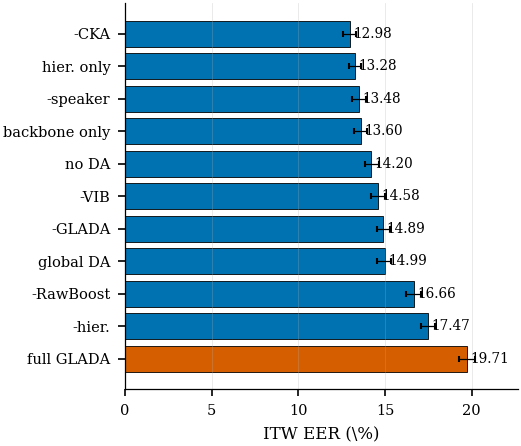

In [4]:
# =====================================================================
# Figure 1: Ablation ITW EER bar chart (single column)
# =====================================================================
configs = ABLATION_ORDER
labels  = ABLATION_LABELS
eers    = [comp_eval.get(c, {}).get('datasets', {}).get('ITW', {}).get('eer', np.nan) for c in configs]
ci_lo   = [comp_eval.get(c, {}).get('datasets', {}).get('ITW', {}).get('ci_low', np.nan) for c in configs]
ci_hi   = [comp_eval.get(c, {}).get('datasets', {}).get('ITW', {}).get('ci_high', np.nan) for c in configs]

order = np.argsort(eers)
labels_s = [labels[i] for i in order]
eers_s   = [eers[i]   for i in order]
err_lo_s = [eers[i] - ci_lo[i] for i in order]
err_hi_s = [ci_hi[i] - eers[i] for i in order]

fig, ax = plt.subplots(figsize=(W_SINGLE, 3.0))
colors = [PALETTE['red'] if c == 'full_glada' else PALETTE['blue'] for c in [configs[i] for i in order]]
ax.barh(range(len(labels_s)), eers_s,
        xerr=[err_lo_s, err_hi_s],
        color=colors, edgecolor='black', linewidth=0.4,
        error_kw=dict(elinewidth=0.6, ecolor='black', capsize=1.5))
ax.set_yticks(range(len(labels_s)))
ax.set_yticklabels(labels_s, fontsize=7)
ax.set_xlabel('ITW EER (\\%)')
ax.set_xlim(0, max(eers_s) * 1.15)
ax.invert_yaxis()  # best on top
ax.grid(axis='x', alpha=0.3, linewidth=0.4)
ax.grid(axis='y', visible=False)
# Annotate the full_glada bar
for i, (lbl, e) in enumerate(zip(labels_s, eers_s)):
    ax.text(e + 0.2, i, f'{e:.2f}', va='center', fontsize=6.5)
fig.tight_layout(pad=0.3)
save_both(fig, 'fig_ablation_bar')
plt.show()

  wrote fig_ablation_heatmap.pdf + fig_ablation_heatmap.png


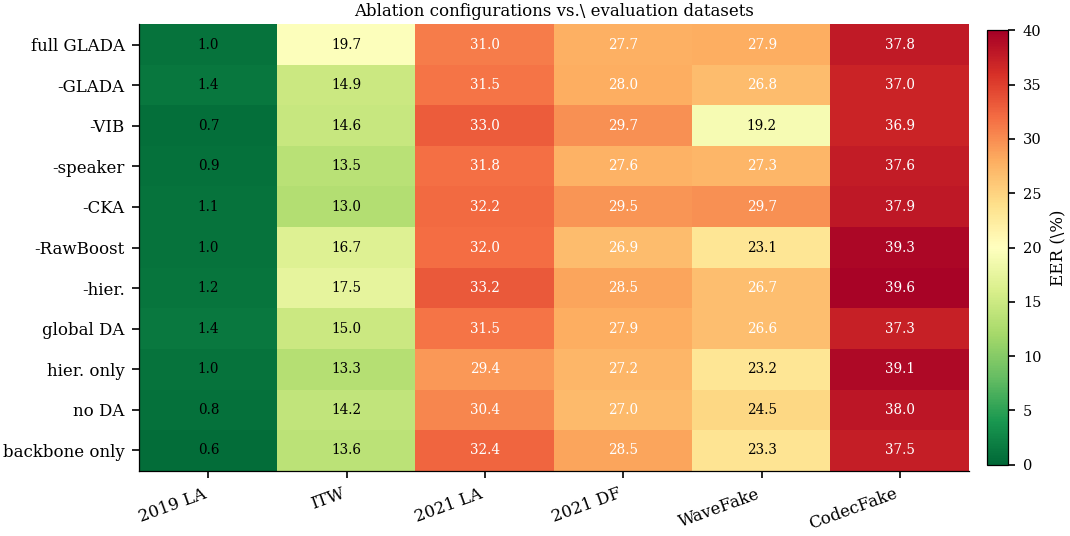

In [5]:
# =====================================================================
# Figure 2: Ablation x Dataset EER heatmap (double column)
# =====================================================================
configs = ABLATION_ORDER
labels  = ABLATION_LABELS
M = np.full((len(configs), len(DATASETS_ORDER)), np.nan)
for i, c in enumerate(configs):
    ds = comp_eval.get(c, {}).get('datasets', {})
    for j, d in enumerate(DATASETS_ORDER):
        if d in ds and 'eer' in ds[d]:
            M[i, j] = ds[d]['eer']

fig, ax = plt.subplots(figsize=(W_DOUBLE, 3.6))
im = ax.imshow(M, aspect='auto', cmap='RdYlGn_r', vmin=0, vmax=max(40, np.nanmax(M)))
ax.set_xticks(range(len(DATASETS_ORDER)))
ax.set_xticklabels(DATASET_LABELS, fontsize=8, rotation=20, ha='right')
ax.set_yticks(range(len(configs)))
ax.set_yticklabels(labels, fontsize=8)
ax.grid(False)

for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M[i, j]
        if np.isnan(v):
            continue
        color = 'white' if v > 25 else 'black'
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', color=color, fontsize=6.5)

cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label('EER (\\%)', fontsize=8)
cbar.ax.tick_params(labelsize=7)
ax.set_title('Ablation configurations vs.\\ evaluation datasets', fontsize=8, pad=4)
fig.tight_layout(pad=0.3)
save_both(fig, 'fig_ablation_heatmap')
plt.show()

  wrote fig_backbone_bar.pdf + fig_backbone_bar.png


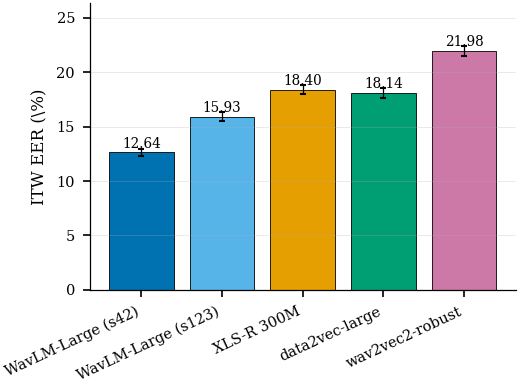

In [6]:
# =====================================================================
# Figure 3: Backbone comparison on ITW with seed variance (single column)
# =====================================================================
bb_ids   = BACKBONE_ORDER
bb_lbls  = BACKBONE_LABELS
bb_eers  = [comp_eval.get(c, {}).get('datasets', {}).get('ITW', {}).get('eer', np.nan) for c in bb_ids]
bb_cilo  = [comp_eval.get(c, {}).get('datasets', {}).get('ITW', {}).get('ci_low', np.nan) for c in bb_ids]
bb_cihi  = [comp_eval.get(c, {}).get('datasets', {}).get('ITW', {}).get('ci_high', np.nan) for c in bb_ids]
bb_err_lo = [e - lo for e, lo in zip(bb_eers, bb_cilo)]
bb_err_hi = [hi - e for e, hi in zip(bb_eers, bb_cihi)]

fig, ax = plt.subplots(figsize=(W_SINGLE, 2.6))
# Emphasize the two WavLM-Large seeds as same family via color grouping
colors = [PALETTE['blue'], PALETTE['sky'], PALETTE['orange'], PALETTE['green'], PALETTE['purple']]
bars = ax.bar(range(len(bb_ids)), bb_eers, yerr=[bb_err_lo, bb_err_hi],
              color=colors, edgecolor='black', linewidth=0.4,
              error_kw=dict(elinewidth=0.6, ecolor='black', capsize=1.5))
ax.set_xticks(range(len(bb_ids)))
ax.set_xticklabels(bb_lbls, rotation=25, ha='right', fontsize=7)
ax.set_ylabel('ITW EER (\\%)')
ax.set_ylim(0, max(bb_eers) * 1.2)
for i, e in enumerate(bb_eers):
    ax.text(i, e + 0.4, f'{e:.2f}', ha='center', fontsize=6.5)
ax.grid(axis='x', visible=False)
fig.tight_layout(pad=0.3)
save_both(fig, 'fig_backbone_bar')
plt.show()

  wrote fig_backbone_heatmap.pdf + fig_backbone_heatmap.png


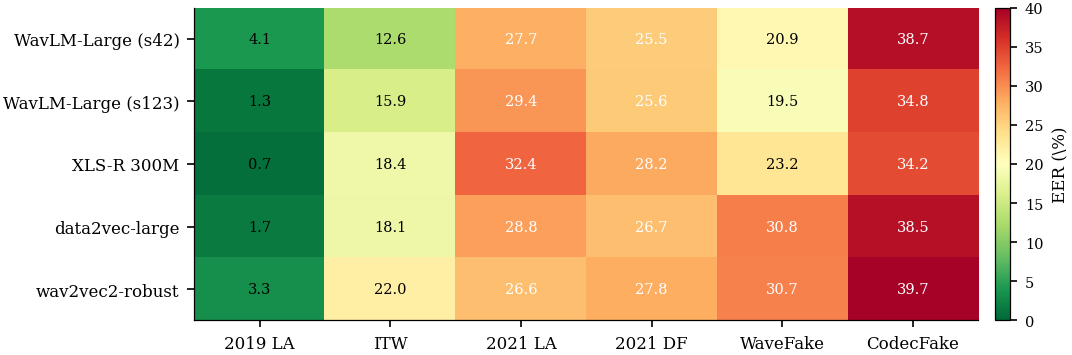

In [7]:
# =====================================================================
# Figure 4: Backbone x Dataset heatmap (double column)
# =====================================================================
M = np.full((len(BACKBONE_ORDER), len(DATASETS_ORDER)), np.nan)
for i, c in enumerate(BACKBONE_ORDER):
    ds = comp_eval.get(c, {}).get('datasets', {})
    for j, d in enumerate(DATASETS_ORDER):
        if d in ds and 'eer' in ds[d]:
            M[i, j] = ds[d]['eer']

fig, ax = plt.subplots(figsize=(W_DOUBLE, 2.4))
im = ax.imshow(M, aspect='auto', cmap='RdYlGn_r', vmin=0, vmax=max(40, np.nanmax(M)))
ax.set_xticks(range(len(DATASETS_ORDER))); ax.set_xticklabels(DATASET_LABELS, fontsize=8)
ax.set_yticks(range(len(BACKBONE_ORDER))); ax.set_yticklabels(BACKBONE_LABELS, fontsize=8)
ax.grid(False)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M[i, j]
        if np.isnan(v): continue
        color = 'white' if v > 25 else 'black'
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', color=color, fontsize=7)
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label('EER (\\%)', fontsize=8)
cbar.ax.tick_params(labelsize=7)
fig.tight_layout(pad=0.3)
save_both(fig, 'fig_backbone_heatmap')
plt.show()

  wrote fig_cs297_matrix.pdf + fig_cs297_matrix.png


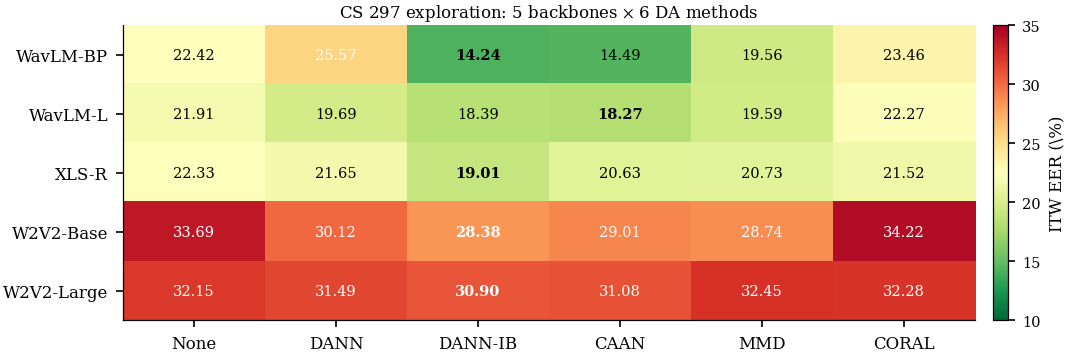

In [8]:
# =====================================================================
# Figure 5: CS 297 5 backbones x 6 methods matrix (double column)
#
# Verified numbers from the submitted paper's Table II (tab:exploration_matrix);
# ITW EER (%), seed 42.  Best per backbone is emphasized in the cell annotation.
# =====================================================================
CS297_ROWS = ['WavLM-BP', 'WavLM-L', 'XLS-R', 'W2V2-Base', 'W2V2-Large']
CS297_COLS = ['None', 'DANN', 'DANN-IB', 'CAAN', 'MMD', 'CORAL']
CS297 = np.array([
    [22.42, 25.57, 14.24, 14.49, 19.56, 23.46],
    [21.91, 19.69, 18.39, 18.27, 19.59, 22.27],
    [22.33, 21.65, 19.01, 20.63, 20.73, 21.52],
    [33.69, 30.12, 28.38, 29.01, 28.74, 34.22],
    [32.15, 31.49, 30.90, 31.08, 32.45, 32.28],
])

fig, ax = plt.subplots(figsize=(W_DOUBLE, 2.4))
im = ax.imshow(CS297, aspect='auto', cmap='RdYlGn_r', vmin=10, vmax=35)
ax.set_xticks(range(len(CS297_COLS))); ax.set_xticklabels(CS297_COLS, fontsize=8)
ax.set_yticks(range(len(CS297_ROWS))); ax.set_yticklabels(CS297_ROWS, fontsize=8)
ax.grid(False)
# Mark per-row best in bold
best = CS297.argmin(axis=1)
for i in range(CS297.shape[0]):
    for j in range(CS297.shape[1]):
        v = CS297[i, j]
        color = 'white' if v > 25 else 'black'
        weight = 'bold' if j == best[i] else 'normal'
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', color=color, fontsize=7, fontweight=weight)
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label('ITW EER (\\%)', fontsize=8)
cbar.ax.tick_params(labelsize=7)
ax.set_title('CS 297 exploration: 5 backbones $\\times$ 6 DA methods', fontsize=8, pad=4)
fig.tight_layout(pad=0.3)
save_both(fig, 'fig_cs297_matrix')
plt.show()

  wrote fig_multiseed_box.pdf + fig_multiseed_box.png


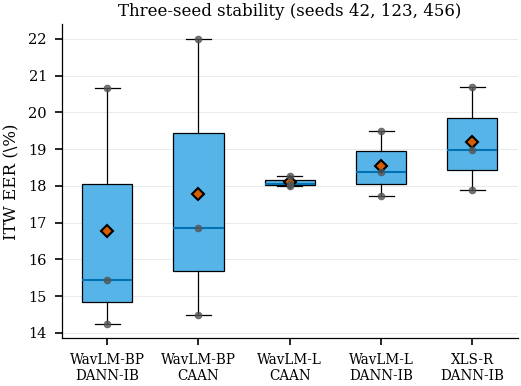

In [9]:
# =====================================================================
# Figure 6: CS 297 multi-seed boxplot (single column)
#
# Verified numbers from the submitted paper's Table IV (tab:exploration_multiseed).
# =====================================================================
SEED_CONFIGS = [
    ('WavLM-BP\nDANN-IB', [14.24, 15.44, 20.66]),
    ('WavLM-BP\nCAAN',    [14.49, 16.85, 22.01]),
    ('WavLM-L\nCAAN',     [18.27, 18.00, 18.04]),
    ('WavLM-L\nDANN-IB',  [18.38, 19.50, 17.72]),
    ('XLS-R\nDANN-IB',    [18.99, 20.69, 17.88]),
]
labels = [x[0] for x in SEED_CONFIGS]
data   = [x[1] for x in SEED_CONFIGS]

fig, ax = plt.subplots(figsize=(W_SINGLE, 2.6))
bp = ax.boxplot(data, widths=0.55, patch_artist=True, showmeans=True,
                meanprops=dict(marker='D', markerfacecolor=PALETTE['red'], markersize=4, markeredgecolor='black'),
                boxprops=dict(facecolor=PALETTE['sky'], linewidth=0.6),
                medianprops=dict(color=PALETTE['blue'], linewidth=1.0),
                whiskerprops=dict(linewidth=0.6), capprops=dict(linewidth=0.6),
                flierprops=dict(marker='o', markersize=3, markerfacecolor=PALETTE['gray']))
# Overlay individual seed points
for i, d in enumerate(data, start=1):
    ax.scatter([i]*len(d), d, s=10, color=PALETTE['gray'], zorder=3, alpha=0.8)
ax.set_xticks(range(1, len(labels)+1))
ax.set_xticklabels(labels, fontsize=6.5)
ax.set_ylabel('ITW EER (\\%)')
ax.set_title('Three-seed stability (seeds 42, 123, 456)', fontsize=8, pad=4)
fig.tight_layout(pad=0.3)
save_both(fig, 'fig_multiseed_box')
plt.show()

  wrote fig_sota_comparison.pdf + fig_sota_comparison.png


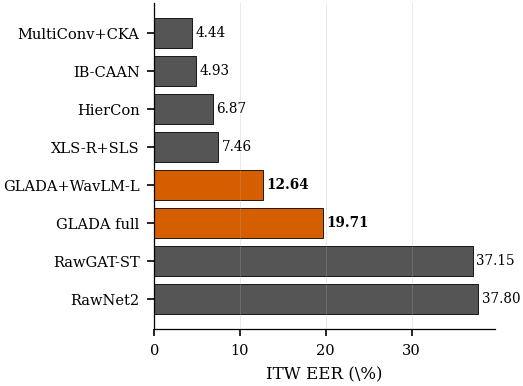

In [10]:
# =====================================================================
# Figure 7: SOTA comparison on ITW (single column)
# =====================================================================
# External numbers verified against original publications; our numbers from comp_eval.
ours_best = comp_eval.get('bb_wavlm-large_s42', {}).get('datasets', {}).get('ITW', {}).get('eer')
ours_full = comp_eval.get('full_glada', {}).get('datasets', {}).get('ITW', {}).get('eer')

SOTA = [
    ('RawNet2',            37.80, False),   # Mueller et al. Interspeech 2022
    ('RawGAT-ST',          37.15, False),   # Mueller et al. Interspeech 2022
    ('XLS-R+SLS',           7.46, False),   # Zhang et al. MM 2024
    ('HierCon',             6.87, False),   # Liang et al. 2026
    ('IB-CAAN',             4.93, False),   # Huang et al. 2025
    ('MultiConv+CKA',       4.44, False),   # Tran et al. MM 2025
    ('GLADA full',      float(ours_full) if ours_full else np.nan, True),
    ('GLADA+WavLM-L',   float(ours_best) if ours_best else np.nan, True),
]
SOTA.sort(key=lambda x: x[1])

fig, ax = plt.subplots(figsize=(W_SINGLE, 2.6))
colors = [PALETTE['red'] if ours else PALETTE['gray'] for _, _, ours in SOTA]
ax.barh(range(len(SOTA)), [e for _, e, _ in SOTA], color=colors, edgecolor='black', linewidth=0.4)
ax.set_yticks(range(len(SOTA)))
ax.set_yticklabels([name for name, _, _ in SOTA], fontsize=7)
ax.set_xlabel('ITW EER (\\%)')
ax.invert_yaxis()
for i, (name, e, ours) in enumerate(SOTA):
    ax.text(e + 0.4, i, f'{e:.2f}', va='center', fontsize=6.5,
            fontweight='bold' if ours else 'normal')
ax.grid(axis='x', alpha=0.3, linewidth=0.4)
ax.grid(axis='y', visible=False)
fig.tight_layout(pad=0.3)
save_both(fig, 'fig_sota_comparison')
plt.show()

21 Phase B / P2 diagnostic runs with history
  wrote fig_phaseb_trajectories.pdf + fig_phaseb_trajectories.png


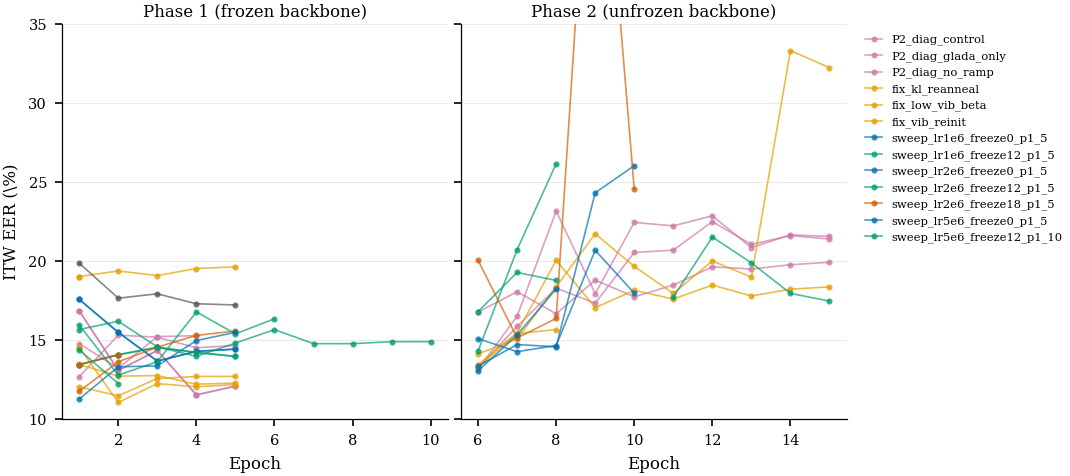

In [11]:
# =====================================================================
# Figure 8: Phase B / Phase 2 diagnostic trajectories (double column)
#
# Plots P1 (frozen) and P2 (unfrozen) ITW EER trajectories for every fix_*
# and sweep_* configuration that has a history.json.  Shows the recurring
# Phase 2 degradation pattern (gradient-shock diagnosis in chap6).
# =====================================================================
phaseb = {k: v for k, v in histories.items() if k.startswith(('fix_', 'sweep_', 'P2_diag_'))}
print(f'{len(phaseb)} Phase B / P2 diagnostic runs with history')

# Group configs into a small number of color families so the chart stays readable
def cfg_color(name):
    if name.startswith('P2_diag_'):   return PALETTE['purple']
    if name.startswith('fix_'):       return PALETTE['orange']
    if 'freeze18' in name:            return PALETTE['red']
    if 'freeze12' in name:            return PALETTE['green']
    if 'freeze0'  in name:            return PALETTE['blue']
    return PALETTE['gray']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(W_DOUBLE, 3.2), sharey=True)
for name, hist in phaseb.items():
    p1x, p1y, p2x, p2y = history_itw_series(hist)
    col = cfg_color(name)
    if p1y:
        ax1.plot(p1x, p1y, marker='o', ms=2, color=col, alpha=0.7, linewidth=0.8)
    if p2y:
        ax2.plot(p2x, p2y, marker='o', ms=2, color=col, alpha=0.7, linewidth=0.8, label=name)
ax1.set_title('Phase 1 (frozen backbone)', fontsize=8, pad=4)
ax2.set_title('Phase 2 (unfrozen backbone)', fontsize=8, pad=4)
ax1.set_xlabel('Epoch'); ax2.set_xlabel('Epoch')
ax1.set_ylabel('ITW EER (\\%)')
ax1.set_ylim(10, 35); ax2.set_ylim(10, 35)
# Compact legend on the right panel
h, l = ax2.get_legend_handles_labels()
if l:
    ax2.legend(h, l, fontsize=5.5, loc='upper left', bbox_to_anchor=(1.02, 1.0),
               frameon=False, handlelength=1.5)
fig.tight_layout(pad=0.3)
save_both(fig, 'fig_phaseb_trajectories')
plt.show()

In [12]:
# =====================================================================
# Figure 9a-k: Per-ablation training curves (one figure per config)
#
# Each figure: two panels (train loss, ITW eval EER) over epochs, with a
# dashed vertical marker at the Phase 1 -> Phase 2 transition.
# Single-column width, designed to fit in the appendix training-curves grid.
# =====================================================================
ABLATION_DIR_MAP = {
    c: f'ablation_{c}' for c in ABLATION_ORDER
}

for cfg, dirname in ABLATION_DIR_MAP.items():
    hist = histories.get(dirname)
    if hist is None:
        print(f'  skip {cfg}: no history')
        continue
    p1x, p1y, p2x, p2y = history_itw_series(hist)
    loss_x, loss_y = history_loss_series(hist, key='total_loss')
    p1_end = max(p1x) if p1x else 0

    fig, (axL, axR) = plt.subplots(1, 2, figsize=(W_SINGLE*1.6, 1.9))

    axL.plot(loss_x, loss_y, color=PALETTE['blue'], marker='.', ms=3, linewidth=0.9)
    axL.axvline(p1_end, linestyle='--', color='gray', linewidth=0.6, alpha=0.7)
    axL.set_xlabel('Epoch'); axL.set_ylabel('Train loss')
    axL.set_title(f'{cfg}: loss', fontsize=8, pad=3)

    if p1y:
        axR.plot(p1x, p1y, color=PALETTE['green'], marker='o', ms=3, linewidth=0.9, label='Phase 1')
    if p2y:
        axR.plot(p2x, p2y, color=PALETTE['red'],   marker='o', ms=3, linewidth=0.9, label='Phase 2')
    axR.axvline(p1_end, linestyle='--', color='gray', linewidth=0.6, alpha=0.7)
    axR.set_xlabel('Epoch'); axR.set_ylabel('ITW EER (\\%)')
    axR.set_title(f'{cfg}: ITW EER', fontsize=8, pad=3)
    axR.legend(fontsize=6, frameon=False, handlelength=1.2)
    fig.tight_layout(pad=0.3)
    save_both(fig, f'fig_training_curves_{cfg}')
    plt.close(fig)

print('Training curves complete.')

  wrote fig_training_curves_full_glada.pdf + fig_training_curves_full_glada.png
  wrote fig_training_curves_no_glada.pdf + fig_training_curves_no_glada.png
  wrote fig_training_curves_no_vib.pdf + fig_training_curves_no_vib.png
  wrote fig_training_curves_no_speaker.pdf + fig_training_curves_no_speaker.png
  wrote fig_training_curves_no_cka.pdf + fig_training_curves_no_cka.png
  wrote fig_training_curves_no_rawboost.pdf + fig_training_curves_no_rawboost.png
  wrote fig_training_curves_no_hier.pdf + fig_training_curves_no_hier.png
  wrote fig_training_curves_global_da_only.pdf + fig_training_curves_global_da_only.png
  wrote fig_training_curves_hierarchical_only.pdf + fig_training_curves_hierarchical_only.png
  wrote fig_training_curves_no_da.pdf + fig_training_curves_no_da.png
  wrote fig_training_curves_backbone_only.pdf + fig_training_curves_backbone_only.png
Training curves complete.


In [13]:
# =====================================================================
# Final cell: Zip FIG_DIR and trigger download
# =====================================================================
ZIP_OUT = '/content/ieee_figures.zip'
if os.path.exists(ZIP_OUT):
    os.remove(ZIP_OUT)
shutil.make_archive(ZIP_OUT.replace('.zip', ''), 'zip', FIG_DIR)
size_mb = os.path.getsize(ZIP_OUT) / 1e6
print(f'Wrote {ZIP_OUT} ({size_mb:.1f} MB)')
print('Contents:')
for name in sorted(os.listdir(FIG_DIR)):
    print(f'  {name}')

try:
    from google.colab import files
    files.download(ZIP_OUT)
except Exception as e:
    print(f'(Auto-download failed: {e})')
    print(f'Manual download: /files{ZIP_OUT}')

# Also copy the archive back to Drive so you can grab it from there if the
# browser blocks the inline download prompt.
DRIVE_COPY = '/content/drive/MyDrive/Jakob/ieee_figures.zip'
shutil.copy(ZIP_OUT, DRIVE_COPY)
print(f'Backup copy saved to {DRIVE_COPY}')

Wrote /content/ieee_figures.zip (4.0 MB)
Contents:
  fig_ablation_bar.pdf
  fig_ablation_bar.png
  fig_ablation_heatmap.pdf
  fig_ablation_heatmap.png
  fig_backbone_bar.pdf
  fig_backbone_bar.png
  fig_backbone_heatmap.pdf
  fig_backbone_heatmap.png
  fig_cs297_matrix.pdf
  fig_cs297_matrix.png
  fig_multiseed_box.pdf
  fig_multiseed_box.png
  fig_phaseb_trajectories.pdf
  fig_phaseb_trajectories.png
  fig_sota_comparison.pdf
  fig_sota_comparison.png
  fig_training_curves_backbone_only.pdf
  fig_training_curves_backbone_only.png
  fig_training_curves_full_glada.pdf
  fig_training_curves_full_glada.png
  fig_training_curves_global_da_only.pdf
  fig_training_curves_global_da_only.png
  fig_training_curves_hierarchical_only.pdf
  fig_training_curves_hierarchical_only.png
  fig_training_curves_no_cka.pdf
  fig_training_curves_no_cka.png
  fig_training_curves_no_da.pdf
  fig_training_curves_no_da.png
  fig_training_curves_no_glada.pdf
  fig_training_curves_no_glada.png
  fig_training_curv

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Backup copy saved to /content/drive/MyDrive/Jakob/ieee_figures.zip
